In [38]:
!pip install xgboost lightgbm catboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression , Lasso ,Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.experimental import enable_hist_gradient_boosting  # Needed for HistGB
from sklearn.ensemble import (RandomForestRegressor,ExtraTreesRegressor,BaggingRegressor,
                              AdaBoostRegressor ,GradientBoostingRegressor,HistGradientBoostingRegressor
                              , VotingRegressor,StackingRegressor)
#import xgboost as xgb
from xgboost import XGBRegressor
from catboost import CatBoostRegressor
#import lightgbm as lgb
from lightgbm import LGBMRegressor

In [39]:
df=pd.read_csv('/content/cars_data.csv')

In [40]:
df

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451
...,...,...,...,...,...,...,...,...
995,Nissan,2018,21052,1.8,Electric,Automatic,4,13831
996,Toyota,2017,105689,2.0,Hybrid,Manual,2,6296
997,Mercedes,2021,183148,3.8,Hybrid,Automatic,2,19708
998,Mazda,2018,189492,1.9,Diesel,Automatic,5,3283


In [41]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Previous_Owners,Price
0,Kia,2015,110373,2.5,Electric,Manual,2,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,5,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,1,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,4,3000
4,BMW,2014,148748,3.5,Diesel,Manual,1,6451


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Brand            1000 non-null   object 
 1   Year             1000 non-null   int64  
 2   Mileage          1000 non-null   int64  
 3   Engine_Size      980 non-null    float64
 4   Fuel_Type        1000 non-null   object 
 5   Transmission     1000 non-null   object 
 6   Previous_Owners  1000 non-null   int64  
 7   Price            1000 non-null   int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 62.6+ KB


In [43]:
df.describe()

,Year,Mileage,Engine_Size,Previous_Owners,Price
count,1000.000000,1000.000000,980.000000,1000.000000,1000.000000
mean,2016.300000,104551.675000,2.494592,3.062000,8473.646000
std,4.056162,56197.795061,0.865230,1.404325,6292.910864
min,2010.000000,5207.000000,1.000000,1.000000,3000.000000
25%,2013.000000,54239.250000,1.800000,2.000000,4069.500000
50%,2016.000000,105298.000000,2.500000,3.000000,6439.000000
75%,2020.000000,155468.250000,3.225000,4.000000,10905.500000
max,2023.000000,199812.000000,4.000000,5.000000,43994.000000


In [44]:
df.drop(['Previous_Owners'],axis=1,inplace=True)

In [45]:
df.columns

Index(['Brand', 'Year', 'Mileage', 'Engine_Size', 'Fuel_Type', 'Transmission',
       'Price'],
      dtype='object')

In [46]:
df.isnull().sum()

,0
Brand,0
Year,0
Mileage,0
Engine_Size,20
Fuel_Type,0
Transmission,0
Price,0


In [47]:
df.duplicated().sum()

np.int64(0)

In [48]:
df.reset_index(drop=True,inplace=True)

In [49]:
from sklearn.impute import SimpleImputer

impute = SimpleImputer(strategy='mean')
df['Engine_Size']=impute.fit_transform(df[['Engine_Size']])

In [50]:
df.isnull().sum()

,0
Brand,0
Year,0
Mileage,0
Engine_Size,0
Fuel_Type,0
Transmission,0
Price,0


In [51]:
df.head()

,Brand,Year,Mileage,Engine_Size,Fuel_Type,Transmission,Price
0,Kia,2015,110373,2.5,Electric,Manual,3000
1,Mercedes,2010,186144,1.3,Electric,Manual,4844
2,Nissan,2018,29574,2.6,Petrol,Manual,6628
3,Kia,2010,139502,2.4,Diesel,Automatic,3000
4,BMW,2014,148748,3.5,Diesel,Manual,6451


<Axes: xlabel='Year', ylabel='Price'>

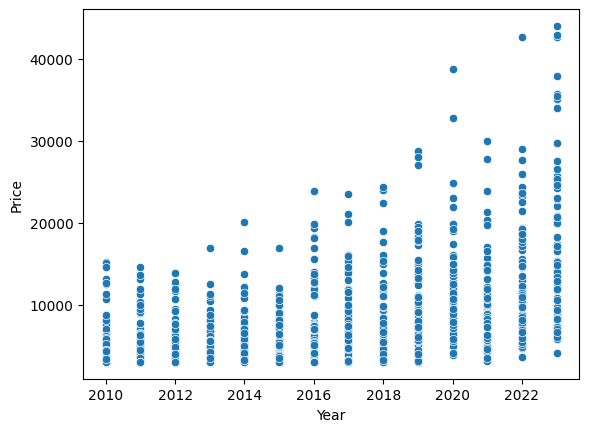

In [52]:
sns.scatterplot(x='Year',y='Price',data=df)


<Axes: xlabel='Mileage', ylabel='Price'>

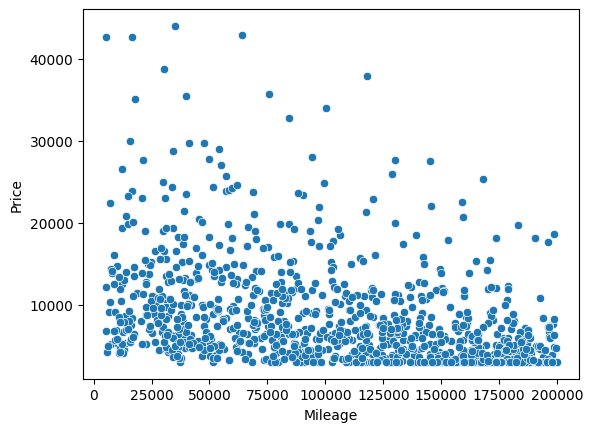

In [53]:
sns.scatterplot(x='Mileage',y='Price',data=df)


<Axes: xlabel='Transmission', ylabel='Price'>

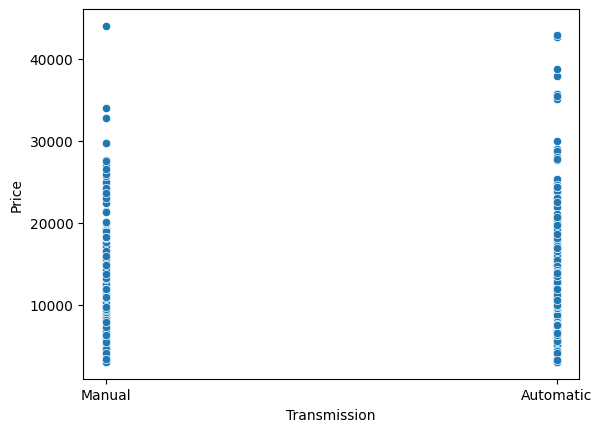

In [54]:
sns.scatterplot(x='Transmission',y='Price',data=df)


In [55]:
df.select_dtypes('object').columns

Index(['Brand', 'Fuel_Type', 'Transmission'], dtype='object')

In [56]:
for col in df.select_dtypes('object').columns:

  print(f'{col}  Unique = ',df[col].nunique())
  print('*'*40)

Brand  Unique =  8
****************************************
Fuel_Type  Unique =  4
****************************************
Transmission  Unique =  2
****************************************


In [57]:
from sklearn.preprocessing import LabelEncoder

In [58]:
lb=LabelEncoder()

In [59]:
for col in ['Brand','Fuel_Type','Transmission']:
  df[col]=lb.fit_transform(df[col])

In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Brand         1000 non-null   int64  
 1   Year          1000 non-null   int64  
 2   Mileage       1000 non-null   int64  
 3   Engine_Size   1000 non-null   float64
 4   Fuel_Type     1000 non-null   int64  
 5   Transmission  1000 non-null   int64  
 6   Price         1000 non-null   int64  
dtypes: float64(1), int64(6)
memory usage: 54.8 KB


In [61]:
from sklearn.model_selection import train_test_split

In [62]:
X = df.drop('Price',axis = 1)
y = df['Price']

In [63]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.1,random_state=42)

In [64]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()


In [65]:
X_train[['Brand','Year','Mileage']] = scaler.fit_transform(
    X_train[['Brand','Year','Mileage']]
)

X_test[['Brand','Year','Mileage']] = scaler.fit_transform(
    X_test[['Brand','Year','Mileage']]
)


In [66]:
models ={
    "Linear Regression":LinearRegression(),
    "Lasso":Lasso(),
    "Ridge":Ridge(),
    "KNN":KNeighborsRegressor(n_neighbors=5,metric='minkowski',p=1), #  minkowski , euclidean , manhattan
    "SVM":SVR(kernel='linear', C=100, gamma=1), # kernel='rbf' / kernel='poly', degree=4 / kernel='sigmoid
    "Decision Tree":DecisionTreeRegressor(criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "Random Forest":RandomForestRegressor(n_estimators=50,criterion='squared_error',max_depth=10), #{"squared_error", "friedman_mse", "absolute_error", "poisson"}
    "ExtraTrees": ExtraTreesRegressor(n_estimators=100, random_state=42),
    "Bagging": BaggingRegressor(estimator=DecisionTreeRegressor(criterion='squared_error',max_depth=10),n_estimators=50, random_state=42),
    "AdaBoost": AdaBoostRegressor(n_estimators=15, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, random_state=42),
    "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=42),
    "XGBoost": XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42, verbosity=0),
    "CatBoost": CatBoostRegressor(verbose=0, iterations=100, learning_rate=0.1, random_state=42),
    "LightGBM": LGBMRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
}

In [67]:
# Metrics function
def regression_metrics(model, X, y_actual):
    y_pred = model.predict(X)
    MAE = mean_absolute_error(y_actual, y_pred)
    MSE = mean_squared_error(y_actual, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_actual, y_pred)
    return MAE, MSE, RMSE, R2

  0%|          | 0/15 [00:00<?, ?it/s]

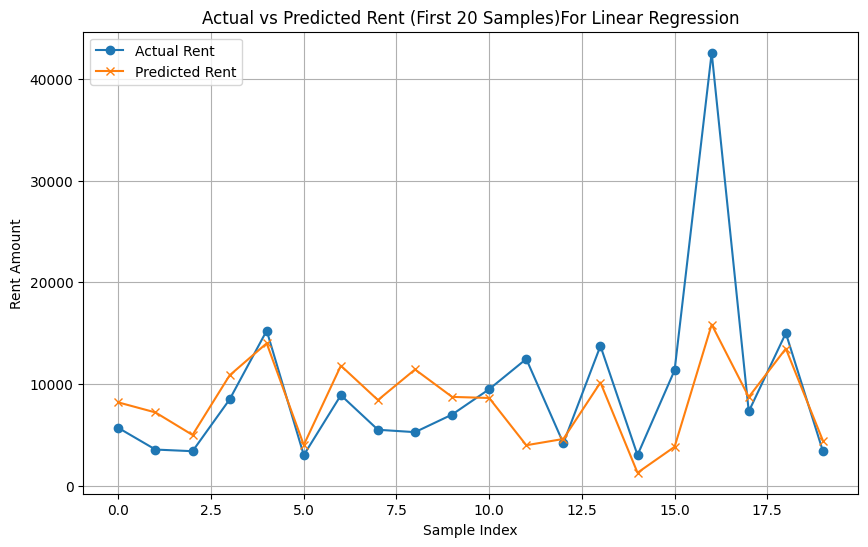

  7%|▋         | 1/15 [00:00<00:04,  3.41it/s]

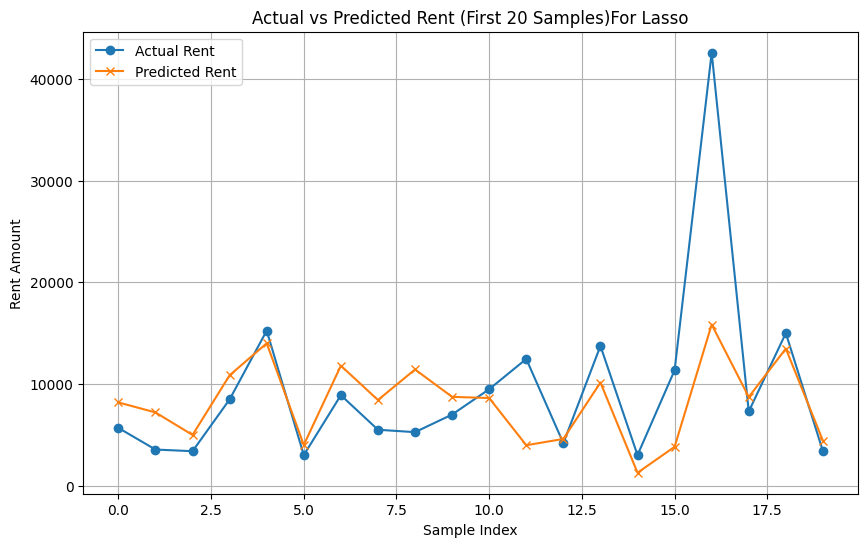

 13%|█▎        | 2/15 [00:00<00:03,  3.67it/s]

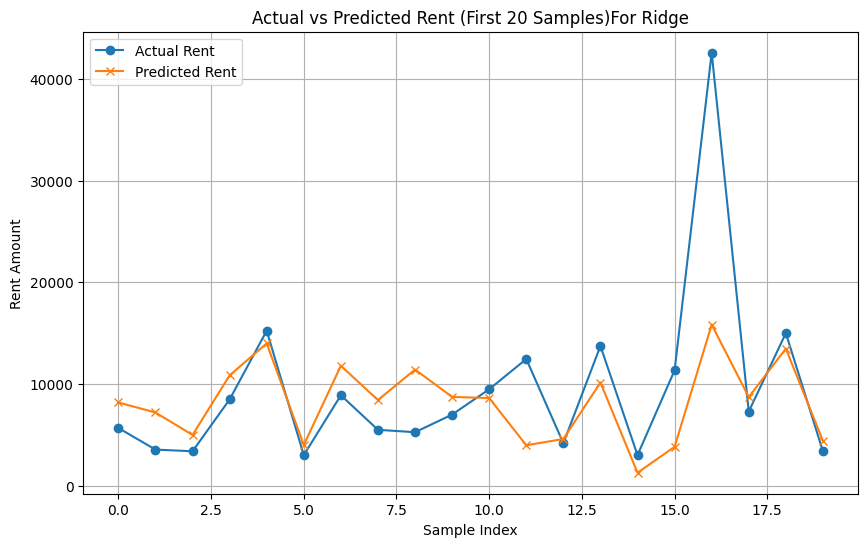

 20%|██        | 3/15 [00:00<00:03,  3.03it/s]

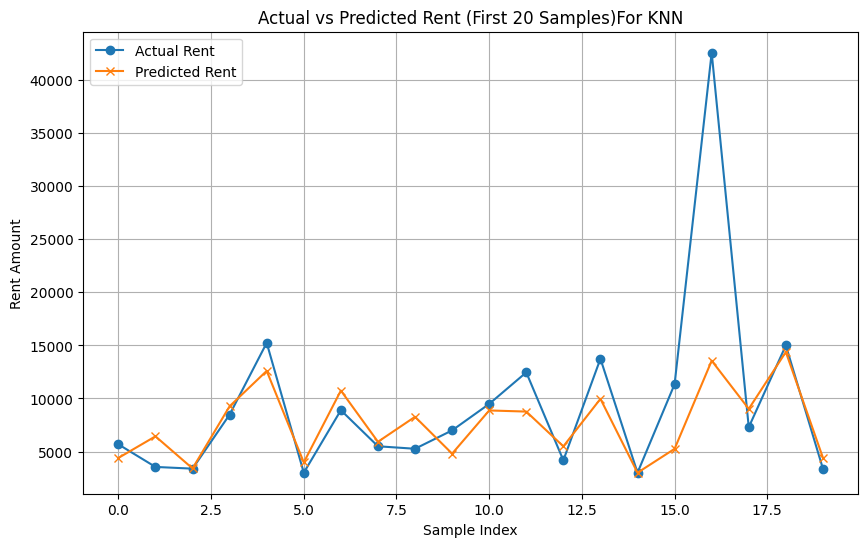

 27%|██▋       | 4/15 [00:01<00:04,  2.52it/s]

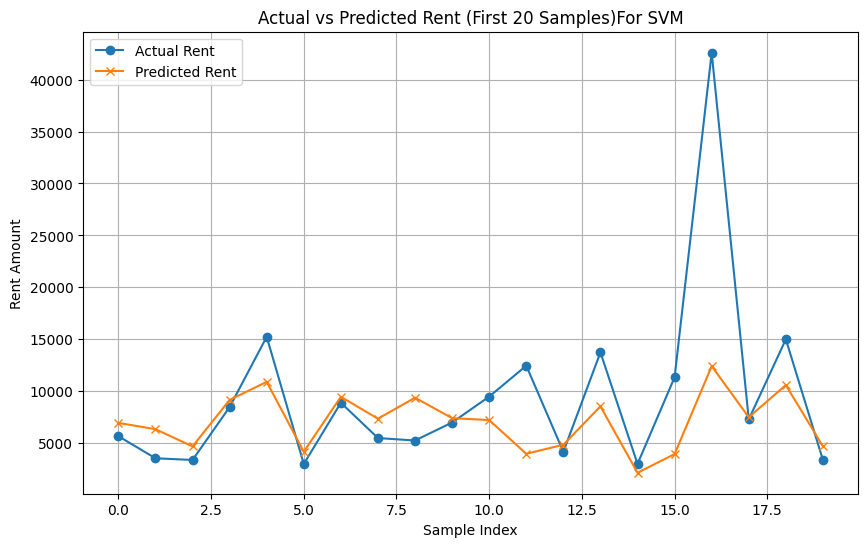

 33%|███▎      | 5/15 [00:02<00:04,  2.18it/s]

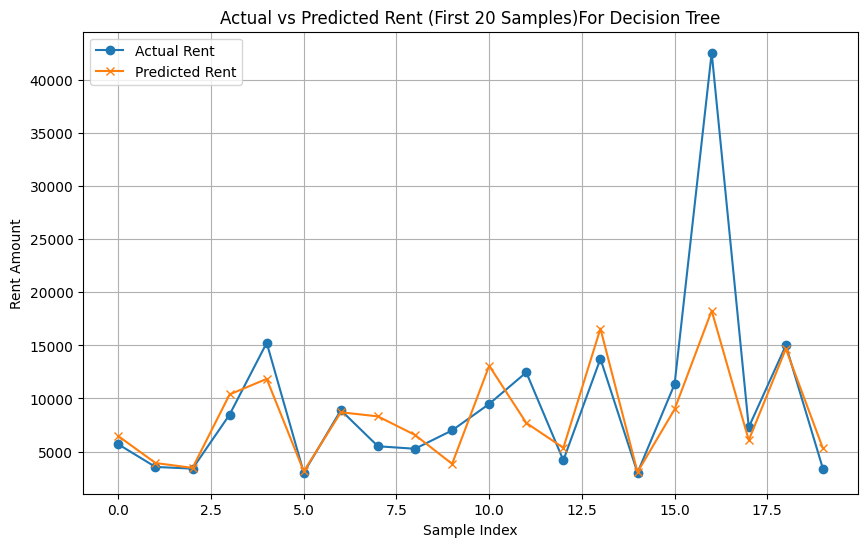

 40%|████      | 6/15 [00:02<00:05,  1.73it/s]

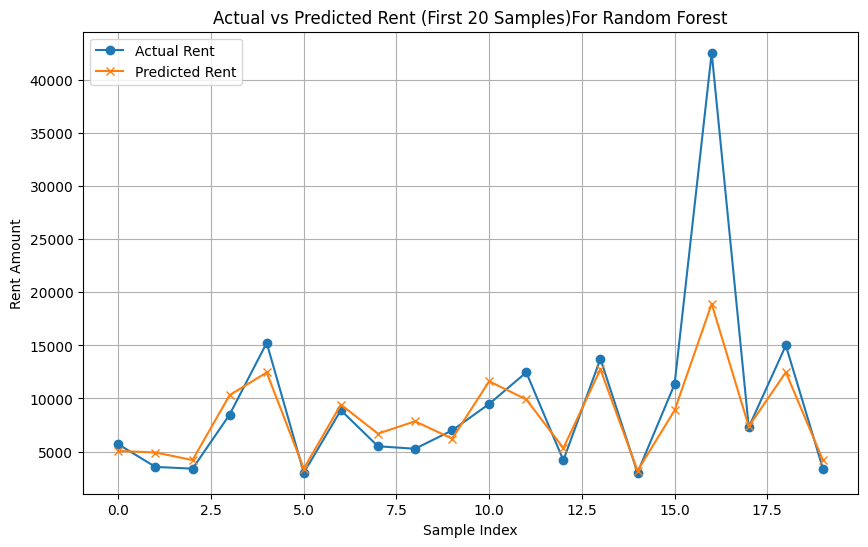

 47%|████▋     | 7/15 [00:05<00:09,  1.23s/it]

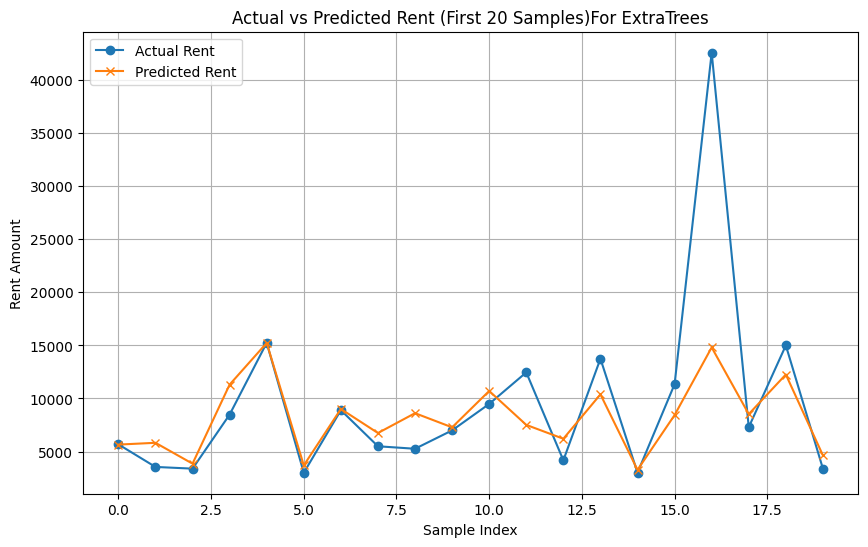

 53%|█████▎    | 8/15 [00:08<00:11,  1.67s/it]

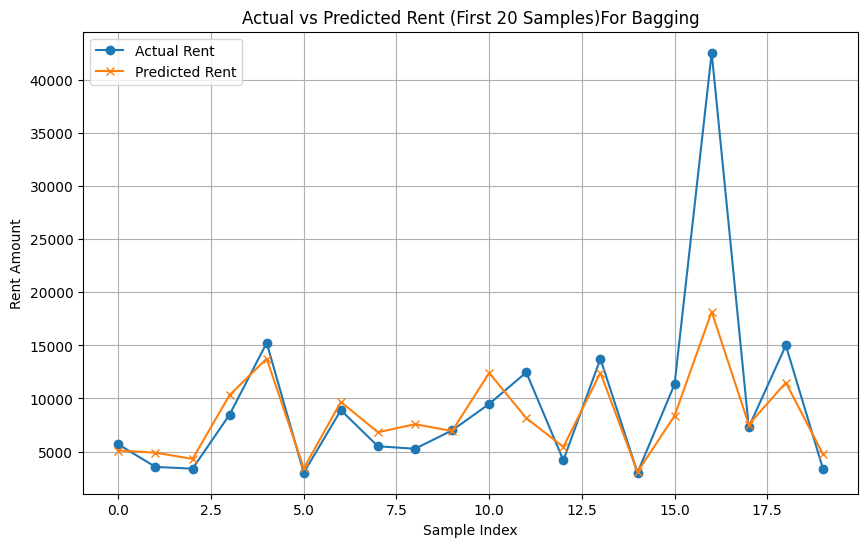

 60%|██████    | 9/15 [00:09<00:09,  1.56s/it]

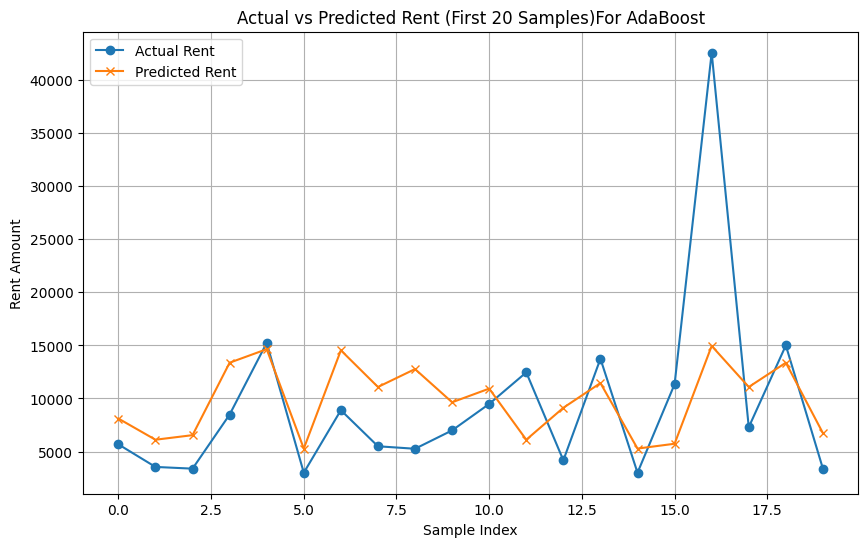

 67%|██████▋   | 10/15 [00:09<00:06,  1.28s/it]

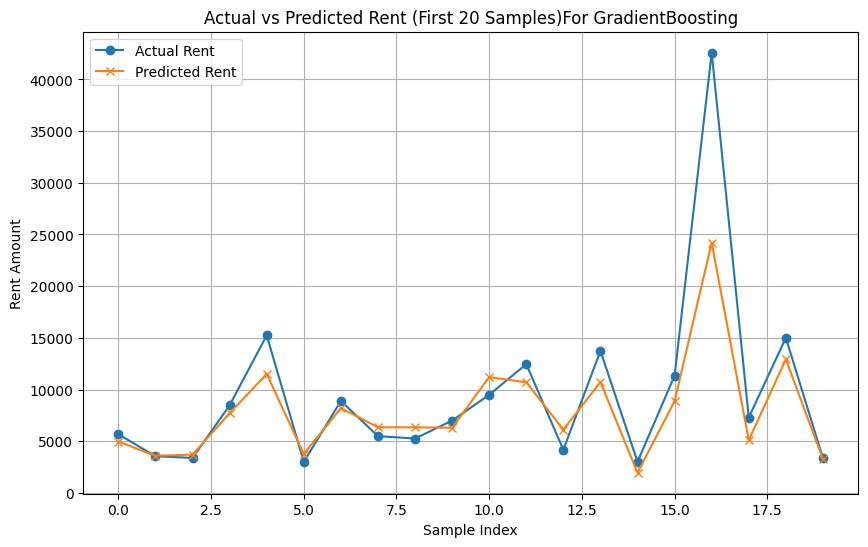

 73%|███████▎  | 11/15 [00:10<00:04,  1.15s/it]

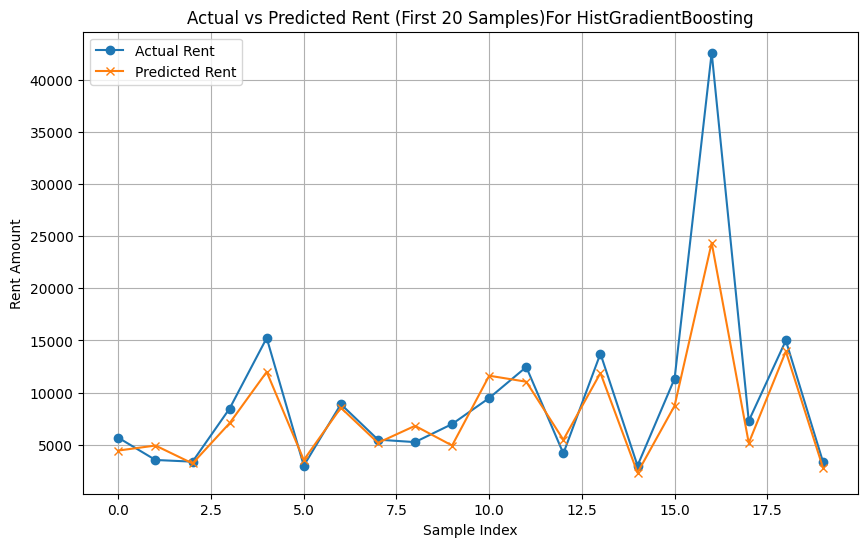

 80%|████████  | 12/15 [00:11<00:03,  1.09s/it]

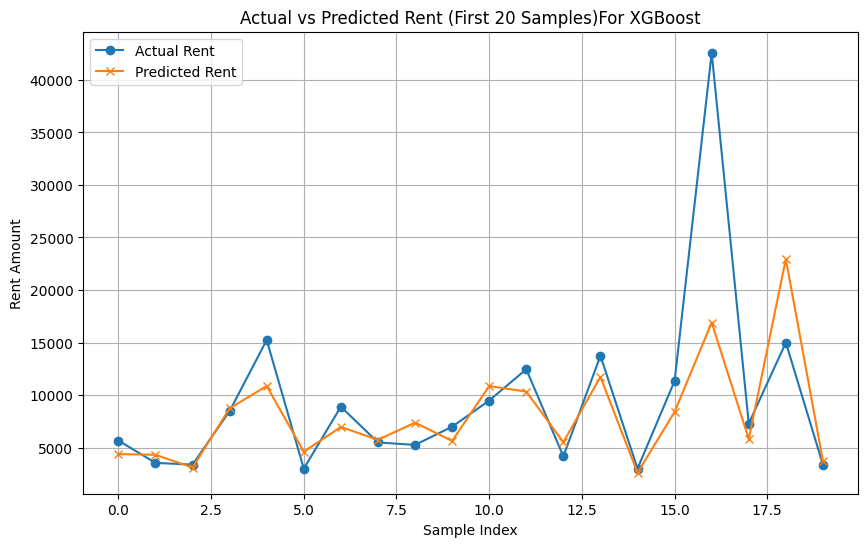

 87%|████████▋ | 13/15 [00:12<00:02,  1.03s/it]

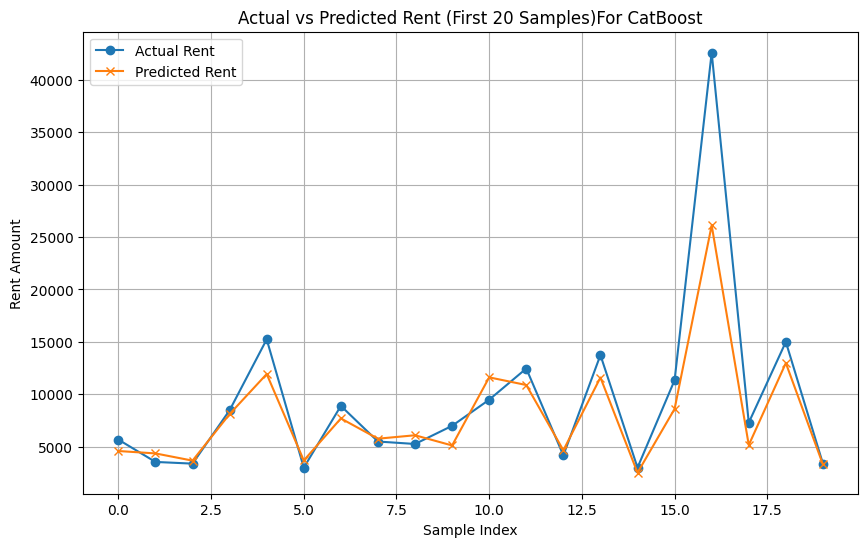

 93%|█████████▎| 14/15 [00:13<00:00,  1.09it/s]

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000234 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 318
[LightGBM] [Info] Number of data points in the train set: 900, number of used features: 6
[LightGBM] [Info] Start training from score 8388.232222


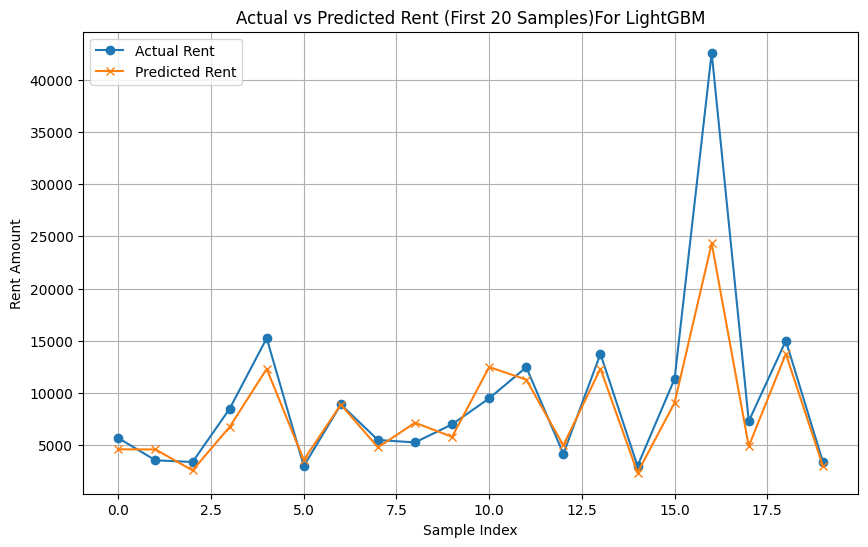

100%|██████████| 15/15 [00:14<00:00,  1.06it/s]


In [68]:
errors={}
for model_name , model in tqdm(models.items()):
    model.fit(X_train,y_train)
    MAE_Train, MSE_Train, RMSE_Train, R_Train = regression_metrics(model, X_train, y_train)
    MAE_Test, MSE_Test, RMSE_Test, R_Test = regression_metrics(model, X_test, y_test)

    errors[model_name] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R_Train,
        "R2 Test":R_Test
    }

    #Plotting Actual vs Predicted for first 20 test samples
    y_test_plot = y_test.values[:20]
    y_pred_plot = model.predict(X_test[:20])

    plt.figure(figsize=(10,6))
    plt.plot(range(20), y_test_plot, label='Actual Rent', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Rent', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Rent Amount')
    plt.title('Actual vs Predicted Rent (First 20 Samples)For '+ model_name)
    plt.legend()
    plt.grid()
    plt.show()

In [69]:
# Create individual regressors
clf1 = LinearRegression()
clf2 = RandomForestRegressor(n_estimators=50, random_state=1)
clf3 = DecisionTreeRegressor(random_state=1)

# Voting Regressors (only averaging is supported)
model1 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

model2 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
])

# Weighted averaging
model3 = VotingRegressor(estimators=[
    ('lr', clf1), ('rf', clf2), ('dt', clf3)
], weights=[2, 1, 2])

# Fit models
model1.fit(X_train, y_train)
model2.fit(X_train, y_train)
model3.fit(X_train, y_train)


# Model 1
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model1, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model1, X_test, y_test)

errors["Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 2
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model2, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model2, X_test, y_test)
errors["Simple Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

# Model 3
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(model3, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(model3, X_test, y_test)
errors["Weighted Voting"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }


In [70]:
# -----------------------------
# Base models for stacking
# -----------------------------
regressors = [
    ('rf', RandomForestRegressor(n_estimators=50, random_state=42)),
    ('gb', GradientBoostingRegressor(n_estimators=50, learning_rate=0.1, random_state=42)),
    ('cat', CatBoostRegressor(iterations=50, learning_rate=0.1, verbose=0)),
    ('lgb', LGBMRegressor(n_estimators=50, learning_rate=0.1, random_state=42))
]

# -----------------------------
# Meta-model
# -----------------------------
meta_regressor = XGBRegressor()

# -----------------------------
# Stacking Models
# -----------------------------
stacking_regressor = StackingRegressor(
    estimators=regressors,
    final_estimator=meta_regressor,
    cv=5,
    passthrough=True,
    n_jobs=-1
)


stacking_regressor.fit(X_train, y_train)
MAE_Train, MSE_Train, RMSE_Train, R2_Train = regression_metrics(stacking_regressor, X_train, y_train)
MAE_test, MSE_test, RMSE_test, R2_Test = regression_metrics(stacking_regressor, X_test, y_test)
errors["Stacking"] = {
        "MAE Train":MAE_Train,
        "MAE Test":MAE_Test,
        "MSE Train":MSE_Train,
        "MSE Test":MSE_Test,
        "RMSE Train":RMSE_Train,
        "RMSE Test":RMSE_Test,
        "R2 Train":R2_Train,
        "R2 Test":R2_Test
    }

In [71]:
errors_df = pd.DataFrame(errors).T.sort_values(by="R2 Test",ascending=False)

In [72]:
errors_df

,MAE Train,MAE Test,MSE Train,MSE Test,RMSE Train,RMSE Test,R2 Train,R2 Test
Stacking,756.826782,1844.145935,2.492112e+06,1.003197e+07,1578.642455,3167.328791,0.934061,0.850170
CatBoost,752.253727,1723.835376,1.072420e+06,9.038003e+06,1035.577341,3006.327083,0.971625,0.835090
LightGBM,588.807370,1844.145935,1.035594e+06,1.003197e+07,1017.641486,3167.328791,0.972599,0.816954
HistGradientBoosting,592.006033,1934.201562,1.018213e+06,1.084313e+07,1009.065372,3292.891564,0.973059,0.802153
GradientBoosting,1015.173707,1926.652081,1.985237e+06,1.106044e+07,1408.984402,3325.724116,0.947473,0.798188
Random Forest,726.313657,2311.899085,1.145220e+06,1.687872e+07,1070.149462,4108.371342,0.969699,0.692026
XGBoost,297.191010,2313.729736,1.615857e+05,1.735502e+07,401.977261,4165.935669,0.995725,0.683335
Bagging,743.269081,2446.028256,1.254446e+06,1.875708e+07,1120.020362,4330.944872,0.966809,0.657753
Simple Voting,1208.708624,1844.145935,2.915012e+06,1.003197e+07,1707.340551,3167.328791,0.922872,0.626891
Voting,1208.708624,1844.145935,2.915012e+06,1.003197e+07,1707.340551,3167.328791,0.922872,0.626891


<Axes: >

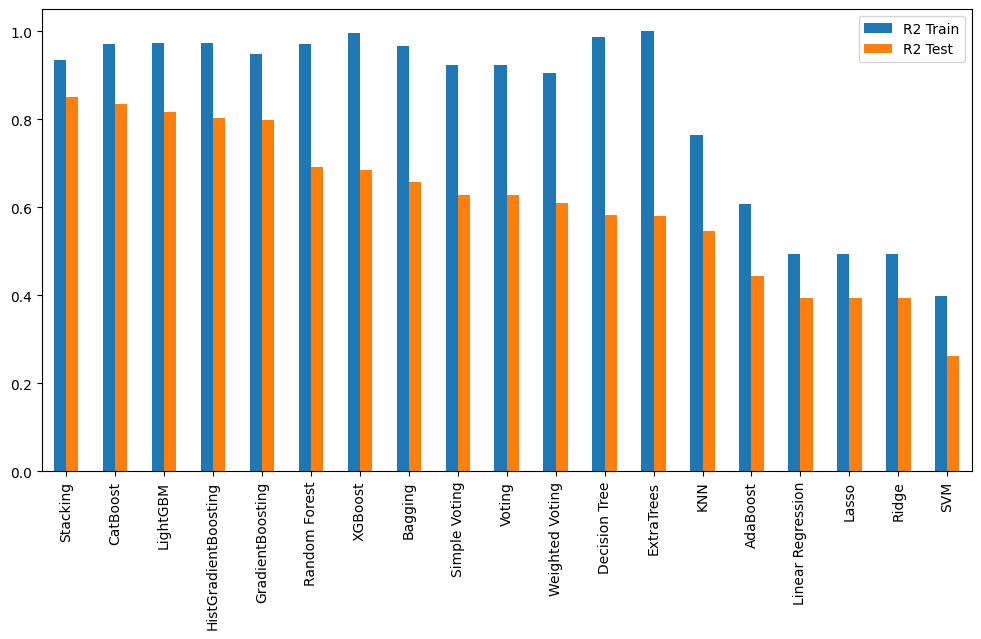

In [73]:
errors_df[["R2 Train", "R2 Test"]].plot.bar(figsize=(12,6))

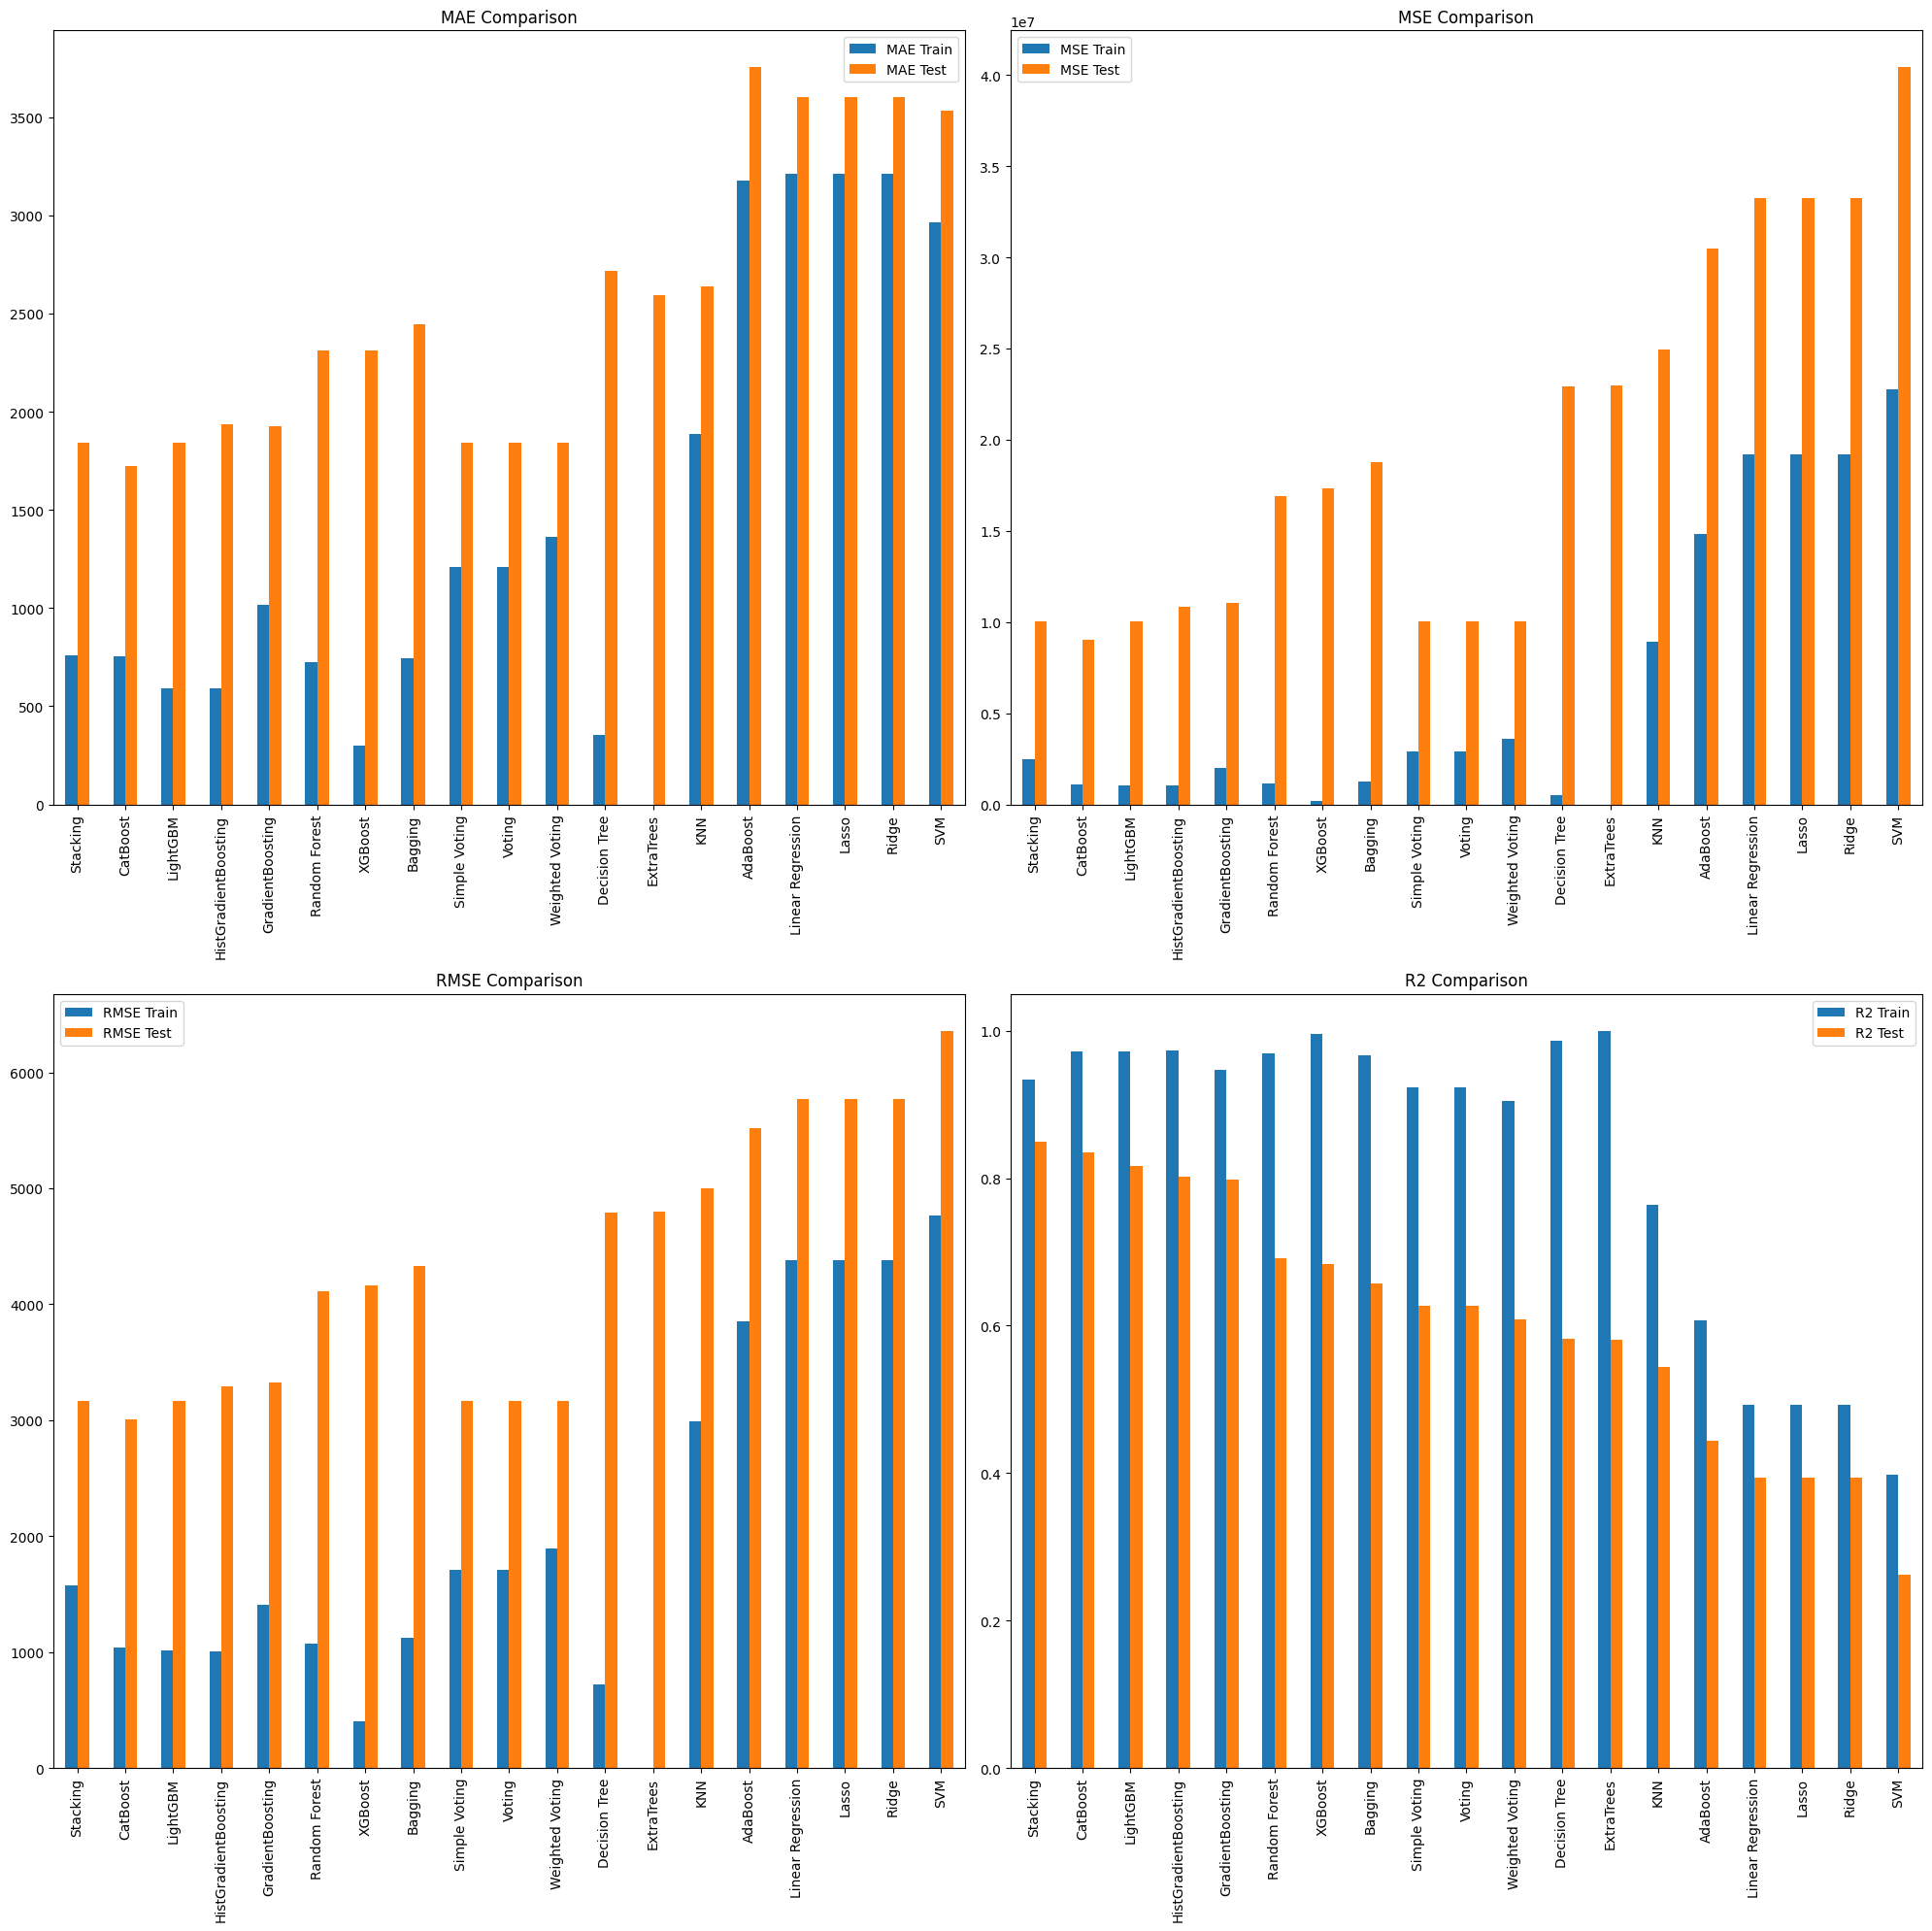

In [74]:
cols = [
    ['MAE Train', 'MAE Test'],
    ['MSE Train', 'MSE Test'],
    ['RMSE Train', 'RMSE Test'],
    ['R2 Train', 'R2 Test']
]

plt.figure(figsize=(20,20))

for i, col in enumerate(cols):
    ax = plt.subplot(2, 2, i+1)
    errors_df[col].plot.bar(ax=ax)
    ax.set_title(col[0].split(" ")[0] + ' Comparison')

plt.tight_layout()
plt.show()